In [ ]:
ROLL_NO = 1024170154 
NAME    = "Kavay Khurana"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"
print("Environment ready for", NAME, f"({ROLL_NO})")

Environment ready for Kavay Khurana (1024170154)


### Starter code (1/2) — dataset generator 

In [23]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Starter code (2/2) — preprocessing pipeline — do not modify

`process_ticket()` is the official pipeline used throughout the assignment: sentence splitting → lowercased word tokens → separate lists for punctuation tokens, stopwords and final tokens.

In [24]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [25]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)
print(f"\nFocus tickets selected by the starter: {FOCUS}")
print(f"Dataset saved to {ROLL_NO}_generated_dataset.csv")

Roll number: 1024170154   Name: Kavay Khurana   Fingerprint: 18B9FB0C   Tickets: 16

Ticket_ID                                                                                           Ticket_Text
      T01                        Printer is running slowly while uploading the file. I don't know what changed.
      T02                                       Python stopped responding after the latest update. Please help.
      T03                                               The email failed to open. It works on another computer.
      T04                                          The server was working yesterday. I don't know what changed.
      T05                   VPN keeps asking for login when I use mobile hotspot. It works on another computer.
      T06                                                             The printer won't print; it isn't jammed.
      T07 I keep getting logged out of the server before the assignment deadline. It works on another computer.
      T08          

---
## Q1 — Preprocessing every ticket

`process_ticket()` is run on all 16 tickets and one table collects, per ticket: number of sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens. A **TOTAL** row follows for the count-based columns. Finally, one selected ticket (the first focus ticket) is shown token by token.

In [26]:
rows, processed = [], {}
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    processed[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique Tokens": len(set(r["tokens"])),
        "Final Tokens": len(r["final"]),
    })

q1 = pd.DataFrame(rows)

all_tokens = [t for r in processed.values() for t in r["tokens"]]
all_final  = [t for r in processed.values() for t in r["final"]]

total = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1["Sentences"].sum(),
    "Tokens": q1["Tokens"].sum(),
    "Punctuation": q1["Punctuation"].sum(),
    "Stopwords": q1["Stopwords"].sum(),
    "Unique Tokens": len(set(all_tokens)),
    "Final Tokens": q1["Final Tokens"].sum(),
}
q1 = pd.concat([q1, pd.DataFrame([total])], ignore_index=True)
display(q1)

print("TOTAL row notes:")
print(f"  * Unique Tokens = distinct token TYPES in the whole corpus ({len(set(all_tokens))}), not a column sum.")
print(f"  * Corpus check: Tokens = Punctuation + Stopwords + Final  ->  "
      f"{total['Tokens']} = {total['Punctuation']} + {total['Stopwords']} + {total['Final Tokens']}  ->  "
      f"{total['Tokens'] == total['Punctuation'] + total['Stopwords'] + total['Final Tokens']}")
print(f"  * Unique final tokens (vocabulary used in Q4): {len(set(all_final))}")

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,6,15,8
1,T02,2,11,2,2,10,7
2,T03,2,12,2,4,11,6
3,T04,2,13,2,5,12,6
4,T05,2,17,2,5,16,10
5,T06,1,11,2,3,10,6
6,T07,2,19,2,8,17,9
7,T08,1,7,2,1,7,4
8,T09,1,9,3,2,9,4
9,T10,2,10,2,3,9,5


TOTAL row notes:
  * Unique Tokens = distinct token TYPES in the whole corpus (82), not a column sum.
  * Corpus check: Tokens = Punctuation + Stopwords + Final  ->  191 = 32 + 61 + 98  ->  True
  * Unique final tokens (vocabulary used in Q4): 55


In [27]:
SELECTED = FOCUS[0]
sel = processed[SELECTED]
print(f"Selected ticket {SELECTED}:")
print(f"   {df.loc[df['Ticket_ID'] == SELECTED, 'Ticket_Text'].iloc[0]}\n")
for label, key in [("Sentences (nltk.sent_tokenize)", "sentences"),
                   ("All tokens (lowercased)", "tokens"),
                   ("Punctuation tokens", "punct"),
                   ("Stopwords", "stops"),
                   ("Final tokens (no punctuation, no stopwords)", "final")]:
    print(f"{label}  (n={len(sel[key])})")
    print("   ", sel[key], "\n")

Selected ticket T11:
   Email was working yesterday since yesterday. I don't know what changed.

Sentences (nltk.sent_tokenize)  (n=2)
    ['Email was working yesterday since yesterday.', "I don't know what changed."] 

All tokens (lowercased)  (n=14)
    ['email', 'was', 'working', 'yesterday', 'since', 'yesterday', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.'] 

Punctuation tokens  (n=2)
    ['.', '.'] 

Stopwords  (n=4)
    ['was', 'i', 'do', 'what'] 

Final tokens (no punctuation, no stopwords)  (n=8)
    ['email', 'working', 'yesterday', 'since', 'yesterday', "n't", 'know', 'changed'] 



**Observation — which "final tokens" are not real dictionary words?**

`process_ticket()` removes punctuation and stopwords, but it cannot repair what the tokenizer did before filtering. In this dataset the odd survivors are:

| final token | count | where it comes from |
|---|---|---|
| `n't` | 6 | `word_tokenize` splits every contracted negation (`don't` → `do` + `n't`, `won't` → `wo` + `n't`, `isn't` → `is` + `n't`). `n't` is not punctuation and is not in the NLTK stopword list, so it passes straight through. It occurs in **T01, T04, T06, T11, T15** and ties with `yesterday` as the most frequent final token of the corpus. |
| `wo` | 1 | the meaningless first half of `won't` (T06) — `wo` is not an English word at all, a classic tokenizer artefact. |
| `3.12` | 1 | the version number in T16 (`Python 3.12 was installed yesterday.`) — kept whole by the Treebank number rule. |
| `4521` | 1 | the ticket number in T08 (`Ticket #4521 is still open.`). |
| `lab-3`, `state-of-the-art` | 1 + 1 | hyphenated forms in T09 that `word_tokenize` keeps as single tokens. |

So `final` is a *filtered* list, not a clean word list: `is_punct()` only deletes tokens made **entirely** of punctuation, so anything else the tokenizer produces survives. The classic artefacts `'s` and `ca` do not appear in these 16 tickets, but they would leak for exactly the same reason.

---
## Q2 — Regex extraction and replacement

All patterns are applied to the **raw** ticket text and to the starter's `TEST_LINES`, using the `re` module:

* `re.findall()` — (1) words longer than 5 letters, (2) numbers that keep decimals and versions such as `95.5` and `2.0.1` as single matches, (3) capitalized words, (4) words beginning with a vowel;
* `re.sub()` — e-mail addresses → `<EMAIL>`, URLs → `<URL>`, phone numbers → `<PHONE>`.

`TEST_LINES` is defined first so that every pattern can be checked against the provided test cases.

In [28]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
print(f"{len(TEST_LINES)} TEST_LINES loaded")

3 TEST_LINES loaded


In [29]:
import re

WORD_GT5 = r"\b[A-Za-z]{6,}\b"

NUM = r"\b(?:0[xX][0-9a-fA-F]+|\d+(?:[.,-]\d+)*)\b"

CAPITAL = r"\b[A-Z][a-z]+\b"

VOWEL = r"\b[aeiouAEIOU][A-Za-z]*\b"

EMAIL_RE = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"

URL_RE   = r"(?:https?://|www\.)[^\s]*[A-Za-z0-9/#%&=+~-]"

PHONE_RE = (r"(?<!\w)(?:\+\d{1,3}[-\s]?)?(?:\(\d{2,4}\)[-\s]?)?"
            r"\d{3,5}[-\s]\d{3,5}(?:[-\s]\d{2,5})?(?!\w)")

def anonymise(text):
    """Mask personal data. Order matters: e-mails first, then URLs, then phone numbers."""
    text = re.sub(EMAIL_RE, "<EMAIL>", text)
    text = re.sub(URL_RE,   "<URL>",   text)
    text = re.sub(PHONE_RE, "<PHONE>", text)
    return text

for _name, _pat in [("WORD_GT5", WORD_GT5), ("NUM", NUM), ("CAPITAL", CAPITAL), ("VOWEL", VOWEL),
                    ("EMAIL", EMAIL_RE), ("URL", URL_RE), ("PHONE", PHONE_RE)]:
    print(f"{_name:9s} {_pat}")

WORD_GT5  \b[A-Za-z]{6,}\b
NUM       \b(?:0[xX][0-9a-fA-F]+|\d+(?:[.,-]\d+)*)\b
CAPITAL   \b[A-Z][a-z]+\b
VOWEL     \b[aeiouAEIOU][A-Za-z]*\b
EMAIL     [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
URL       (?:https?://|www\.)[^\s]*[A-Za-z0-9/#%&=+~-]
PHONE     (?<!\w)(?:\+\d{1,3}[-\s]?)?(?:\(\d{2,4}\)[-\s]?)?\d{3,5}[-\s]\d{3,5}(?:[-\s]\d{2,5})?(?!\w)


In [30]:
raw_texts = list(df["Ticket_Text"])
extract_counts = {"words>5": [], "numbers": [], "capitalized": [], "vowel-initial": []}
for tid, text in zip(df["Ticket_ID"], raw_texts):
    w5  = re.findall(WORD_GT5, text)
    num = re.findall(NUM, text)
    cap = re.findall(CAPITAL, text)
    vow = re.findall(VOWEL, text)
    extract_counts["words>5"] += w5
    extract_counts["numbers"] += num
    extract_counts["capitalized"] += cap
    extract_counts["vowel-initial"] += vow
    print(f"{tid}: {text}")
    print(f"    words>5  : {w5}")
    print(f"    numbers  : {num}")
    print(f"    capitals : {cap}")
    print(f"    vowels   : {vow}")

summary = pd.DataFrame([{"Pattern": k, "Total matches": len(v), "Unique matches": len(set(v)),
                         "Example": ", ".join(v[:4])} for k, v in extract_counts.items()])
print()
display(summary)

T01: Printer is running slowly while uploading the file. I don't know what changed.
    words>5  : ['Printer', 'running', 'slowly', 'uploading', 'changed']
    numbers  : []
    capitals : ['Printer']
    vowels   : ['is', 'uploading', 'I']
T02: Python stopped responding after the latest update. Please help.
    words>5  : ['Python', 'stopped', 'responding', 'latest', 'update', 'Please']
    numbers  : []
    capitals : ['Python', 'Please']
    vowels   : ['after', 'update']
T03: The email failed to open. It works on another computer.
    words>5  : ['failed', 'another', 'computer']
    numbers  : []
    capitals : ['The', 'It']
    vowels   : ['email', 'open', 'It', 'on', 'another']
T04: The server was working yesterday. I don't know what changed.
    words>5  : ['server', 'working', 'yesterday', 'changed']
    numbers  : []
    capitals : ['The']
    vowels   : ['I']
T05: VPN keeps asking for login when I use mobile hotspot. It works on another computer.
    words>5  : ['asking', 'mo

,Pattern,Total matches,Unique matches,Example
0,words>5,63,36,"Printer, running, slowly, uploading"
1,numbers,3,3,"4521, 3, 3.12"
2,capitalized,24,10,"Printer, Python, Please, The"
3,vowel-initial,44,24,"is, uploading, I, after"


In [31]:
print("=== re.findall on raw TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST_LINE {i}: {line}")
    print(f"    words>5  : {re.findall(WORD_GT5, line)}")
    print(f"    numbers  : {re.findall(NUM, line)}")
    print(f"    capitals : {re.findall(CAPITAL, line)}")
    print(f"    vowels   : {re.findall(VOWEL, line)}")

print("\n=== the same lines after re.sub masking (much cleaner) ===")
for i, line in enumerate(TEST_LINES, 1):
    masked = anonymise(line)
    print(f"\nTEST_LINE {i} masked: {masked}")
    print(f"    words>5  : {re.findall(WORD_GT5, masked)}")
    print(f"    numbers  : {re.findall(NUM, masked)}")
    print(f"    capitals : {re.findall(CAPITAL, masked)}")
    print(f"    vowels   : {re.findall(VOWEL, masked)}")

=== re.findall on raw TEST_LINES ===

TEST_LINE 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
    words>5  : ['helpdesk', 'thapar', 'thapar', 'thapar']
    numbers  : []
    capitals : ['Mail']
    vowels   : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

TEST_LINE 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
    words>5  : ['Version']
    numbers  : ['91', '98765', '43210', '91-98765-43210', '0175-239-3201', '2.0.1', '95.5', '1,250']
    capitals : ['Call', 'Version', 'Rs']
    vowels   : ['or', 'is']

TEST_LINE 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
    words>5  : []
    numbers  : ['5.30']
    capitals : ['The']
    vowels   : ['of', 'art', 'isn', 'open', 'in', 'at']

=== the same lines after re.sub masking (much cleaner) ===

TEST_LINE 1 masked: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
    words>

In [32]:
print("=== re.sub on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"{i}. before: {line}")
    print(f"   after : {anonymise(line)}\n")

print("=== re.sub on the 16 tickets ===")
leaks = []
for tid, text in zip(df["Ticket_ID"], raw_texts):
    masked = anonymise(text)
    print(f"{tid}: {masked}")
    if re.search(r"\S+@\S+", masked) or re.search(r"(?:https?://|www\.)", masked):
        leaks.append(tid)

print("\nSanity checks")
print("  * TEST_LINES: no '@' and no '://' left after substitution      ->",
      all("@" not in anonymise(l) and "://" not in anonymise(l) for l in TEST_LINES))
print("  * Tickets with a surviving e-mail/URL                          ->", leaks or "none")
print("  * None of my 16 tickets contains contact data, so masking leaves them unchanged;")
print("    TEST_LINES (which do contain e-mails, URLs and phones) verify the replacements.")

=== re.sub on TEST_LINES ===
1. before: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
   after : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

2. before: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
   after : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

3. before: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
   after : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

=== re.sub on the 16 tickets ===
T01: Printer is running slowly while uploading the file. I don't know what changed.
T02: Python stopped responding after the latest update. Please help.
T03: The email failed to open. It works on another computer.
T04: The server was working yesterday. I don't know what changed.
T05: VPN keeps asking for login when I use mobile hotspot. It works on another computer.
T06: The printer won't prin

In [33]:
from nltk.tokenize import RegexpTokenizer
cap_tok = RegexpTokenizer(CAPITAL)

detail_rows = []
total_caps = sentence_initial = 0
for tid, text in zip(df["Ticket_ID"], raw_texts):
    caps = cap_tok.tokenize(text)
    sents = sent_tokenize(text)
    si = sum(1 for s in sents if cap_tok.tokenize(s))
    total_caps += len(caps)
    sentence_initial += si
    detail_rows.append({"Ticket_ID": tid, "capitalized": len(caps),
                        "sentence-initial": si, "genuine": len(caps) - si,
                        "matches": caps})

display(pd.DataFrame(detail_rows))
print(f"TOTAL capitalized matches      : {total_caps}")
print(f"  of which sentence-initial    : {sentence_initial}  ({sentence_initial/total_caps:.1%})")
print(f"  genuinely capitalized        : {total_caps - sentence_initial}  ({(total_caps-sentence_initial)/total_caps:.1%})")
genuine = [c for r in detail_rows for c in r["matches"][r["sentence-initial"]:] if c]
print("  the genuine ones             :", sorted(set(c for r in detail_rows for c in r['matches'] if c in ('Lab', 'Python'))))

,Ticket_ID,capitalized,sentence-initial,genuine,matches
0,T01,1,1,0,[Printer]
1,T02,2,2,0,"[Python, Please]"
2,T03,2,2,0,"[The, It]"
3,T04,1,1,0,[The]
4,T05,1,1,0,[It]
5,T06,1,1,0,[The]
6,T07,1,1,0,[It]
7,T08,1,1,0,[Ticket]
8,T09,2,1,1,"[The, Lab]"
9,T10,2,2,0,"[The, Please]"


TOTAL capitalized matches      : 24
  of which sentence-initial    : 22  (91.7%)
  genuinely capitalized        : 2  (8.3%)
  the genuine ones             : ['Lab', 'Python']


**Observation — how many "capitalized words" are only sentence starts?**

**24 `CAPITAL` matches in total; 22 of them (91.7% ≈ 92%) are the first token of their sentence** — artefacts of sentence position, not proper nouns. Only **2 are genuinely capitalized inside a sentence**: `Lab` (from `Lab-3`, T09) and `Python` (T15; its other occurrence in T02 happens to sit at the start of a sentence, so it is counted as sentence-initial there).

Two design decisions shape these numbers:

* `CAPITAL = \b[A-Z][a-z]+\b` matches *Title-case* words only. All-caps acronyms (`VPN`, `LMS`, `MATLAB`) are excluded on purpose — otherwise every acronym would count as "capitalized" and the statistic would be meaningless.
* The 16 tickets are short (mostly two sentences), so almost every match is simply an opener: `The`, `I`, `It`, `Please`, `Is`, `This`, `Email`, `Ticket`, `Python`, `Printer`.

**Conclusion:** "capitalized" is a poor proxy for "proper noun" in IT-support text; a feature built on it would be dominated by sentence starts. Any extraction of proper nouns should either drop the first token of each sentence or match a curated list of brand/acronym names instead.

One more extraction caveat visible in the `TEST_LINES` output: run **without** masking, the patterns reach *inside* e-mails and URLs (`thapar`, `edu`, `univ`, `ac`, `in` are matched as words/vowel-words). Masking with the `re.sub` patterns first removes those false matches — which is exactly why anonymisation belongs at the start of a real ticket pipeline.

---
## Q3 — Custom tokenization

`my_tokenize(text)` is built from **one** `RegexpTokenizer` pattern. The pattern is an alternation of named alternatives so that each "semantic atom" survives as a single token:

* contractions — `isn't`, `don't`, `won't`
* hyphenated words — `Wi-Fi`, `state-of-the-art`, `lab-3`
* decimals and versions — `95.5`, `2.0.1`
* e-mail addresses, URLs and phone numbers

In [34]:
EMAIL_T = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
URL_T   = r"(?:https?://|www\.)[^\s]*[A-Za-z0-9/#%&=+~-]"
PHONE_T = (r"(?:\+\d{1,3}[-\s]?)?(?:\(\d{2,4}\)[-\s]?)?"
           r"\d{3,5}[-\s]\d{3,5}(?:[-\s]\d{2,5})?")
NUMV_T  = r"\d+(?:\.\d+)+"
WORD_T  = r"[A-Za-z0-9]+(?:['\u2019-][A-Za-z0-9]+)*"
ANY_T   = r"[^\sA-Za-z0-9]"

MY_PATTERN = "|".join([EMAIL_T, URL_T, PHONE_T, NUMV_T, WORD_T, ANY_T])
my_tok = RegexpTokenizer(MY_PATTERN)

def my_tokenize(text):
    """Tokenize with a single RegexpTokenizer pattern (see MY_PATTERN)."""
    return my_tok.tokenize(text)

print("MY_PATTERN:")
print(MY_PATTERN)
print()
for line in TEST_LINES:
    print("line :", line)
    print("mine :", my_tokenize(line))
    print("nltk :", word_tokenize(line))
    print()

MY_PATTERN:
[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?:https?://|www\.)[^\s]*[A-Za-z0-9/#%&=+~-]|(?:\+\d{1,3}[-\s]?)?(?:\(\d{2,4}\)[-\s]?)?\d{3,5}[-\s]\d{3,5}(?:[-\s]\d{2,5})?|\d+(?:\.\d+)+|[A-Za-z0-9]+(?:['\u2019-][A-Za-z0-9]+)*|[^\sA-Za-z0-9]

line : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
mine : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
nltk : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

line : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
mine : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
nltk : ['Call', '+91', '9

In [35]:
cmp_rows, diff_examples = [], []
for tid, text in zip(df["Ticket_ID"], raw_texts):
    mine = my_tokenize(text)
    nltk_toks = word_tokenize(text)
    same = mine == nltk_toks
    cmp_rows.append({"Ticket_ID": tid, "my_tokenize": len(mine),
                     "word_tokenize": len(nltk_toks), "identical?": same})
    if not same:
        diff_examples.append((tid, text, mine, nltk_toks))

display(pd.DataFrame(cmp_rows))
print(f"Tickets tokenized differently: {len(diff_examples)} of {len(df)} -> "
      f"{[tid for tid, *_ in diff_examples]}\n")
for tid, text, mine, nltk_toks in diff_examples:
    print(f"{tid}: {text}")
    print(f"   my_tokenize  ({len(mine):2d}): {mine}")
    print(f"   word_tokenize({len(nltk_toks):2d}): {nltk_toks}\n")

,Ticket_ID,my_tokenize,word_tokenize,identical?
0,T01,15,16,False
1,T02,11,11,True
2,T03,12,12,True
3,T04,12,13,False
4,T05,17,17,True
5,T06,9,11,False
6,T07,19,19,True
7,T08,7,7,True
8,T09,9,9,True
9,T10,10,10,True


Tickets tokenized differently: 5 of 16 -> ['T01', 'T04', 'T06', 'T11', 'T15']

T01: Printer is running slowly while uploading the file. I don't know what changed.
   my_tokenize  (15): ['Printer', 'is', 'running', 'slowly', 'while', 'uploading', 'the', 'file', '.', 'I', "don't", 'know', 'what', 'changed', '.']
   word_tokenize(16): ['Printer', 'is', 'running', 'slowly', 'while', 'uploading', 'the', 'file', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

T04: The server was working yesterday. I don't know what changed.
   my_tokenize  (12): ['The', 'server', 'was', 'working', 'yesterday', '.', 'I', "don't", 'know', 'what', 'changed', '.']
   word_tokenize(13): ['The', 'server', 'was', 'working', 'yesterday', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

T06: The printer won't print; it isn't jammed.
   my_tokenize  ( 9): ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
   word_tokenize(11): ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is'

**Answer — how the two tokenizers differ, with examples from this dataset**

**5 of the 16 tickets — T01, T04, T06, T11, T15 — are tokenized differently**, and all five differ for the same reason: they contain a contracted negation. The `TEST_LINES` expose further differences:

| # | input | `my_tokenize` | `word_tokenize` | why |
|---|---|---|---|---|
| 1 | `isn't` (TEST_LINE 3), `don't` (T01/T04/T11/T15), `won't` (T06) | one token each: `["isn't"]`, `["don't"]`, `["won't"]` | split: `['is', "n't"]`, `['do', "n't"]`, `['wo', "n't"]` | Penn-Treebank convention: the clitic `n't` becomes its own token. My `WORD_T` rule allows an internal apostrophe, so the contraction stays whole. The split even creates the non-word `wo`, and it pushes `is`/`do` into the stopword bucket while `n't` becomes one of the most frequent *final* tokens in Q5. |
| 2 | `it.helpdesk@thapar.edu` (TEST_LINE 1) | one token | `['it.helpdesk', '@', 'thapar.edu']` | the EMAIL alternative matches the whole address before any word rule can break it at `@`; Treebank splits these addresses into pieces. Keeping addresses atomic is what makes the Q2 masking safe. |
| 3 | `https://lms.thapar.edu/help` (TEST_LINE 1) | one token | `['https', ':', '//lms.thapar.edu/help']` | same principle for URLs — scheme + host + path survive as one unit. |
| 4 | `+91 98765 43210` (TEST_LINE 2) | one token | `['+91', '98765', '43210']` | my PHONE alternative accepts spaces between digit groups; Treebank keeps hyphenated numbers (`0175-239-3201`) whole but splits the space-separated Indian mobile format. |
| 5 | `1,250`, `p.m.`, `again...` | `['1', ',', '250']`, `['p', '.', 'm', '.']`, `['again', '.', '.', '.']` | `['1,250']`, `['p.m.']`, `['again', '...']` | trade-offs in the other direction: my pattern has no rule for thousands separators or abbreviations, and `ANY_T` emits one character per punctuation mark. These are pieces of punctuation that `is_punct()` removes anyway, whereas Treebank's `p.m.`/`...` survive as odd "word" tokens. |

**Takeaway.** `word_tokenize()` is a general-purpose Treebank tokenizer tuned for well-formed English prose; `my_tokenize()` is tuned for IT-support text where e-mail addresses, URLs, phone numbers and versions are semantic atoms. Which one is "right" depends on the downstream task — for masking PII, building search indexes over identifiers, or matching version strings, the custom pattern wins; for plain bag-of-words over prose, both are acceptable.

---
## Q4 — Stemming and lemmatization on the unique final tokens

The **55 unique final tokens** are processed with four methods:

* `PorterStemmer`
* `LancasterStemmer`
* `RegexpStemmer` — with a suffix rule chosen from this dataset's own words (evidence printed below)
* `WordNetLemmatizer` — with POS tags obtained from `nltk.pos_tag()` (each token is tagged inside its ticket's token stream, taking its most frequent contextual tag)

The required table shows **only the words whose four outputs are not all identical**.

In [36]:
unique_final = sorted(set(all_final))
print(f"{len(unique_final)} unique final tokens:")
print(unique_final)

CANDIDATES = ["ing", "ed", "es", "s", "ly", "er", "ion", "ment", "able", "ness", "al", "ance", "ent"]
print("\nSuffix evidence (only suffixes with at least 2 suitable words):")
evidence = {}
for suf in CANDIDATES:
    ws = [w for w in unique_final if w.endswith(suf) and len(w) > len(suf) + 2]
    if len(ws) >= 2:
        evidence[suf] = ws
        print(f"  -{suf:<4} {len(ws):2d} word(s) -> {ws}")

55 unique final tokens:
['3.12', '4521', 'another', 'asking', 'assignment', 'changed', 'closed', 'computer', 'deadline', 'email', 'failed', 'file', 'getting', 'help', 'hotspot', 'installed', 'jammed', 'keep', 'keeps', 'know', 'lab', 'lab-3', 'latest', 'logged', 'login', 'mobile', "n't", 'occurs', 'open', 'please', 'print', 'printer', 'problem', 'python', 'resolve', 'responding', 'running', 'server', 'since', 'slowly', 'solution', 'state-of-the-art', 'still', 'stopped', 'syncing', 'ticket', 'update', 'uploading', 'urgent', 'use', 'vpn', 'wo', 'working', 'works', 'yesterday']

Suffix evidence (only suffixes with at least 2 suitable words):
  -ing   7 word(s) -> ['asking', 'getting', 'responding', 'running', 'syncing', 'uploading', 'working']
  -ed    7 word(s) -> ['changed', 'closed', 'failed', 'installed', 'jammed', 'logged', 'stopped']
  -s     3 word(s) -> ['keeps', 'occurs', 'works']
  -er    4 word(s) -> ['another', 'computer', 'printer', 'server']
  -ent   2 word(s) -> ['assignment

In [37]:
from nltk import pos_tag
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from collections import Counter, defaultdict

tag_votes = defaultdict(Counter)
for r in processed.values():
    finalset = set(r["final"])
    for w, t in pos_tag(r["tokens"]):
        if w in finalset:
            tag_votes[w][t] += 1

def best_tag(w):
    """Most frequent contextual POS tag of w; fall back to tagging w alone."""
    if tag_votes.get(w):
        return tag_votes[w].most_common(1)[0][0]
    return pos_tag([w])[0][1]

TAG2WN = {"NN": "n", "NNS": "n", "NNP": "n", "NNPS": "n",
          "VB": "v", "VBD": "v", "VBG": "v", "VBN": "v", "VBP": "v", "VBZ": "v",
          "JJ": "a", "JJR": "a", "JJS": "a",
          "RB": "r", "RBR": "r", "RBS": "r"}

SUFFIX = "ing"
rx_stemmer = RegexpStemmer(SUFFIX + "$")

porter, lancaster, wnl = PorterStemmer(), LancasterStemmer(), WordNetLemmatizer()

stem_rows = []
for w in unique_final:
    tag = best_tag(w)
    wn  = TAG2WN.get(tag, "n")
    stem_rows.append({"Word": w, "POS": tag, "WN pos": wn,
                      "Porter": porter.stem(w),
                      "Lancaster": lancaster.stem(w),
                      "Regexp(-ing)": rx_stemmer.stem(w),
                      "WordNet lemma": wnl.lemmatize(w, pos=wn)})
stem_df = pd.DataFrame(stem_rows)

display(stem_df)

out_cols = ["Porter", "Lancaster", "Regexp(-ing)", "WordNet lemma"]
diff_mask = stem_df[out_cols].nunique(axis=1) > 1
diff_df = stem_df[diff_mask].reset_index(drop=True)
print(f"Words where the four methods do NOT all agree: {len(diff_df)} of {len(stem_df)}")
display(diff_df)

,Word,POS,WN pos,Porter,Lancaster,Regexp(-ing),WordNet lemma
0,3.12,CD,n,3.12,3.12,3.12,3.12
1,4521,CD,n,4521,4521,4521,4521
2,another,DT,n,anoth,anoth,another,another
3,asking,VBG,v,ask,ask,ask,ask
4,assignment,JJ,a,assign,assign,assignment,assignment
5,changed,VBD,v,chang,chang,changed,change
6,closed,VBN,v,close,clos,closed,close
7,computer,NN,n,comput,comput,computer,computer
8,deadline,NN,n,deadlin,deadlin,deadline,deadline
9,email,NN,n,email,email,email,email


Words where the four methods do NOT all agree: 32 of 55


,Word,POS,WN pos,Porter,Lancaster,Regexp(-ing),WordNet lemma
0,another,DT,n,anoth,anoth,another,another
1,assignment,JJ,a,assign,assign,assignment,assignment
2,changed,VBD,v,chang,chang,changed,change
3,closed,VBN,v,close,clos,closed,close
4,computer,NN,n,comput,comput,computer,computer
5,deadline,NN,n,deadlin,deadlin,deadline,deadline
6,failed,VBD,v,fail,fail,failed,fail
7,file,NN,n,file,fil,file,file
8,getting,VBG,v,get,get,gett,get
9,installed,VBN,v,instal,instal,installed,instal


**Suffix choice for the `RegexpStemmer`.** The evidence cell counts candidate suffixes among the 55 words: `-ing` → 7 words (`asking, getting, responding, running, syncing, uploading, working`), `-ed` → 7 words (`changed, closed, failed, installed, jammed, logged, stopped`), `-er` → 4 (`another, computer, printer, server`), `-s` → 3 (`keeps, occurs, works`), `-ent` → 2. I chose **`ing$`** because:

1. all seven `-ing` words are present participles of verbs — one clean, inflectional morphological family — so the rule is a fair test, and it is justified by far more than the required two words;
2. its behaviour is the most instructive: the failures it produces (`running → runn`, `getting → gett`) show exactly why a literal string deletion is not a stemmer, and its misses (`changed`, `stopped`, … stay untouched) show that a single suffix cannot normalise the vocabulary.

The alternatives are substantively worse: `-er` would fire on `another, computer, printer, server`, where `-er` is *derivational* (noun-forming) rather than inflectional — stripping it destroys real words and merges them with unrelated verbs; `-s` covers only three words.

**What the comparison table shows (32 of 55 words disagree):**

* **Porter** is conservative and mostly sane: `running → run`, `getting → get` (its measure function handles the doubled consonant that the regex cannot), `changed → chang`; but it still leaves non-words such as `slowly → slowli`, `another → anoth`, `please → pleas`.
* **Lancaster** is the most aggressive: `use → us` (a false merge with the pronoun!), `since → sint`, `server → serv`, `solution → solv`, `open → op`, `mobile → mobl`, `urgent → urg`, `occurs → occ`, `closed → clos`.
* **RegexpStemmer(`ing$`)** strips a literal `ing`: correct for `working/uploading/asking/responding/syncing`, but **over-stems** `running → runn` and `getting → gett`, and **under-stems** everything ending differently (`changed`, `stopped`, `closed`, `failed`, … are untouched).
* **WordNet lemmatization with POS** produces real dictionary words whenever the tag is right: `keeps → keep`, `works → work`, `occurs → occur`, `closed → close`, `failed → fail`, `changed → change`, `latest → late`; and it correctly leaves true lemmas alone (`printer`, `server`, `mobile`, `urgent`).

---
## Q5 — Corpus statistics

Four token streams are compared:

* **S1** — all tokens from `process_ticket()`
* **S2** — S1 without punctuation tokens
* **S3** — final tokens (no punctuation, no stopwords)
* **S4** — S3 after Porter stemming

For each stream: total tokens, unique tokens and TTR. Then the top-10 words of S1 and S3, the log(rank) vs log(frequency) plot for S3, and the top-5 bigrams of S1 and S3.

In [38]:
from collections import Counter

S1 = list(all_tokens)
S2 = [t for t in S1 if not is_punct(t)]
S3 = list(all_final)
S4 = [porter.stem(t) for t in S3]

def corpus_stats(name, seq):
    total, uniq = len(seq), len(set(seq))
    return {"Set": name, "Total tokens": total, "Unique tokens": uniq, "TTR": round(uniq / total, 4)}

q5 = pd.DataFrame([corpus_stats("S1 — all tokens", S1),
                   corpus_stats("S2 — no punctuation", S2),
                   corpus_stats("S3 — final tokens", S3),
                   corpus_stats("S4 — S3 + Porter", S4)])
display(q5)

,Set,Total tokens,Unique tokens,TTR
0,S1 — all tokens,191,82,0.4293
1,S2 — no punctuation,159,76,0.4780
2,S3 — final tokens,98,55,0.5612
3,S4 — S3 + Porter,98,53,0.5408


In [39]:
top1 = Counter(S1).most_common(10)
top3 = Counter(S3).most_common(10)
print(f"{'rank':<6}{'S1 (all tokens)':<24}{'S3 (final tokens)':<24}")
for i, ((w1, c1), (w3, c3)) in enumerate(zip(top1, top3), 1):
    print(f"{i:<6}{w1 + ' (' + str(c1) + ')':<24}{w3 + ' (' + str(c3) + ')':<24}")

rank  S1 (all tokens)         S3 (final tokens)       
1     . (27)                  n't (6)                 
2     the (14)                yesterday (6)           
3     is (6)                  know (4)                
4     i (6)                   changed (4)             
5     n't (6)                 another (4)             
6     yesterday (6)           server (4)              
7     it (5)                  working (4)             
8     was (5)                 printer (3)             
9     do (4)                  python (3)              
10    know (4)                stopped (3)             


In [40]:
from nltk.util import bigrams

print("Top 5 bigrams of S1 (all tokens):")
for bg, c in Counter(bigrams(S1)).most_common(5):
    print(f"   {c:2d} x  {bg}")

print("\nTop 5 bigrams of S3 (final tokens):")
for bg, c in Counter(bigrams(S3)).most_common(5):
    print(f"   {c:2d} x  {bg}")

Top 5 bigrams of S1 (all tokens):
    9 x  ('.', 'the')
    5 x  ('.', 'i')
    5 x  ('yesterday', '.')
    4 x  ('i', 'do')
    4 x  ('do', "n't")

Top 5 bigrams of S3 (final tokens):
    4 x  ("n't", 'know')
    4 x  ('know', 'changed')
    4 x  ('working', 'yesterday')
    3 x  ('works', 'another')
    3 x  ('another', 'computer')


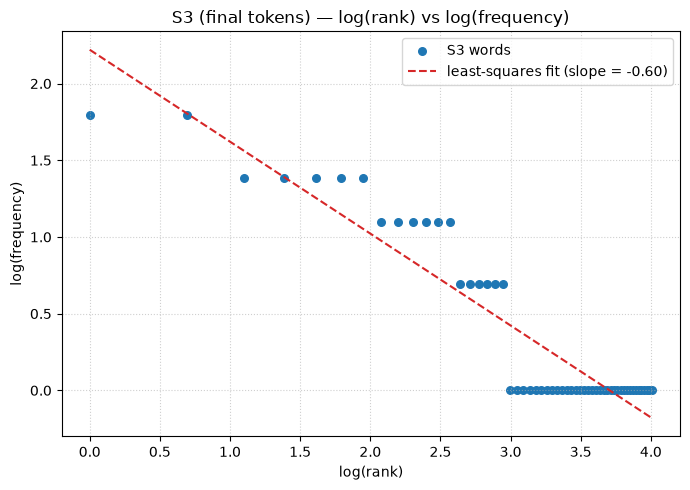

Fitted Zipf slope for S3: -0.599   (ideal Zipf = -1; a shallower slope is expected for a 98-token corpus)


In [41]:
%matplotlib inline
import math
import matplotlib.pyplot as plt

ordered = Counter(S3).most_common()
ranks   = list(range(1, len(ordered) + 1))
counts  = [c for _, c in ordered]
logs_r  = [math.log(r) for r in ranks]
logs_f  = [math.log(c) for c in counts]

n = len(logs_r)
mx, my = sum(logs_r) / n, sum(logs_f) / n
slope = sum((x - mx) * (y - my) for x, y in zip(logs_r, logs_f)) / sum((x - mx) ** 2 for x in logs_r)
intercept = my - slope * mx
fit = [slope * x + intercept for x in logs_r]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(logs_r, logs_f, s=30, color="#1f77b4", label="S3 words")
ax.plot(logs_r, fit, "--", color="#d62728", label=f"least-squares fit (slope = {slope:.2f})")
ax.set_xlabel("log(rank)")
ax.set_ylabel("log(frequency)")
ax.set_title("S3 (final tokens) — log(rank) vs log(frequency)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.savefig("Assignment7_zipf_S3.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Fitted Zipf slope for S3: {slope:.3f}   (ideal Zipf = -1; a shallower slope is expected for a 98-token corpus)")

**Reading the statistics.**

* Punctuation dominates the raw stream — `.` alone occurs 27 times out of 191 S1 tokens — yet contributes only a handful of distinct types, so removing it raises TTR from 0.4293 to 0.4780. Removing the (few, highly frequent) stopwords raises it further to **0.5612** on S3.
* The top-10 lists show the same effect: S1 is led by `.` (27), `the` (14), `is`/`i` (6 each); after filtering, S3 is led by content words — `n't` (6), `yesterday` (6), `know`/`changed`/`another`/`server`/`working` (4 each).
* The S1 bigrams are full of sentence-boundary artefacts (`('.', 'the')` ×9, `('.', 'i')` ×5, `('yesterday', '.')` ×5) because punctuation is included and bigrams are counted across sentence boundaries. The S3 bigrams are meaningful phrases: `("n't", 'know')`, `('know', 'changed')`, `('working', 'yesterday')` — the fingerprint of the generated "I don't know what changed." endings.
* The log–log plot is roughly linear but with a fitted slope of about **−0.6**, i.e. shallower than the ideal Zipf slope of −1. This is expected for a *tiny* corpus (98 tokens, 55 types, max frequency 6): with so few tokens, the tail of the distribution has not yet developed, and TTR/rank curves are strongly size-dependent.

---
## Q6 — Interpretation

The cell below prints the exact values cited in the four answers.

In [42]:
print("(a) TTR S1 =", round(len(set(S1)) / len(S1), 4),
      "-> S3 =", round(len(set(S3)) / len(S3), 4),
      "-> S4 =", round(len(set(S4)) / len(S4), 4),
      f"| types S3 -> S4: {len(set(S3))} -> {len(set(S4))} with {len(S3)} tokens unchanged")

b_example = "The printer won't print; it isn't jammed."
print("\n(b)", b_example)
print("    my_tokenize :", my_tokenize(b_example))
print("    word_tokenize:", word_tokenize(b_example))
print("    affected tickets:", [tid for tid, *_ in diff_examples])

print("\n(c) Lancaster('use') =", lancaster.stem("use"),
      "| Lancaster('since') =", lancaster.stem("since"),
      "| Lancaster('server') =", lancaster.stem("server"),
      "| Porter('slowly') =", porter.stem("slowly"))

print("\n(d) Lancaster('printer') =", lancaster.stem("printer"),
      "| Porter('printer') =", porter.stem("printer"),
      "| WordNet lemma('printer', 'n') =", wnl.lemmatize("printer", pos="n"))

(a) TTR S1 = 0.4293 -> S3 = 0.5612 -> S4 = 0.5408 | types S3 -> S4: 55 -> 53 with 98 tokens unchanged

(b) The printer won't print; it isn't jammed.
    my_tokenize : ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
    word_tokenize: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']
    affected tickets: ['T01', 'T04', 'T06', 'T11', 'T15']

(c) Lancaster('use') = us | Lancaster('since') = sint | Lancaster('server') = serv | Porter('slowly') = slowli

(d) Lancaster('printer') = print | Porter('printer') = printer | WordNet lemma('printer', 'n') = printer


(a) **Why does TTR change from S1 to S4 in this dataset?**

TTR goes **0.4293 (S1) → 0.5612 (S3) → 0.5408 (S4)**. Two opposite forces act:

1. *Filtering raises TTR.* S1 contains punctuation and stopwords, which are the classic "high frequency, low variety" items: `.` appears 27 times but adds one type, `the` 14 times, `is`/`i`/`it`/`was` several times each. Deleting these frequent-but-repetitive tokens raises the ratio to 0.5612 on S3.
2. *Stemming lowers TTR slightly.* Porter merges inflected forms into a shared stem without deleting a single token: `works → work` (joining `working → work`) and `keeps → keep` reduce the type count 55 → **53** while the token count stays **98**, so TTR slips to 0.5408.

Net effect: TTR grows from S1 to S4 because the increase from removing punctuation/stopwords outweighs the small decrease from stemming. The lesson is that TTR is not a fixed property of a text: it depends on length and on every preprocessing decision, so a TTR computed before stemming and one computed after are not the same quantity, and TTRs of corpora of different sizes are not directly comparable (a 98-token corpus is intrinsically "type-rich" compared to a real helpdesk stream).

(b) **One example where `word_tokenize()` and `my_tokenize()` differ.**

Take T06: *"The printer won't print; it isn't jammed."*

```
my_tokenize  : ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']            (9 tokens)
word_tokenize: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']   (11 tokens)
```

The difference is **clitic splitting**: the Penn-Treebank convention treats `n't` as an independent token, so `won't` and `isn't` fall apart into stem + clitic. This has real consequences: `wo` is not an English word and pollutes the vocabulary (it is one of the 55 S3 tokens), the negation is detached from the word it negates, a search for the string `"won't"` fails on a bag of words built with `word_tokenize`, and `n't` becomes one of the most frequent final tokens in Q5 purely because of this rule. My tokenizer keeps each contraction whole, so the negation stays a single meaningful, searchable feature. The same split explains every ticket that the two tokenizers disagree on (T01, T04, T06, T11, T15).

(c) **One example where stemming produces an undesirable result.**

`LancasterStemmer().stem("use") = "us"`. "Use" occurs in T05 (*"when I use mobile hotspot"*). Lancaster's aggressive rule strips the final `e` and produces `us` — a completely different English word (the pronoun). A vocabulary-based classifier would merge two unrelated meanings into one type, and a search for "us" would return every ticket about *using* the LMS. The same table shows the failure mode repeatedly: `since → sint`, `server → serv`, `solution → solv`, `mobile → mobl`, `occurs → occ`. Porter has milder but still real errors: `slowly → slowli` is a non-word.

(d) **One example where POS-aware lemmatization preserves meaning better than stemming.**

The word **`printer`** (`NN`, noun) occurs in T01, T06 and T14:

* `LancasterStemmer` → **`print`**: it deletes the noun-forming suffix `-er` and merges the *device* with the genuinely different *verb* `print` ("The printer won't **print**" would become the same type as "printer").
* `RegexpStemmer(ing$)` and `PorterStemmer` → `printer`: unchanged — but only because they happen not to have a rule that fires, not because they know the word.
* `WordNetLemmatizer("printer", pos="n")` → **`printer`**: because WordNet's lexicon *knows* `printer` is already a dictionary head word, no suffix is removed.

The general reason: stemming is purely orthographic — it can only delete characters and cannot know when to stop — whereas lemmatization is lexicon-driven: it looks the word up, uses the POS tag to pick the right reading, and removes only genuine inflectional endings (`-s`, `-ed`, `-ing`). That is why `printer`, `server`, `mobile` and `urgent` survive lemmatization intact but are damaged by at least one stemmer.